In [2]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import cifar10
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input
from keras.models import Sequential
from keras.layers import Input, Flatten, Dense, Dropout
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.optimizers import Adam
from sklearn.model_selection import train_test_split

In [3]:
# 1. Load CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

In [4]:
# 2. Select airplane (0), automobile (1), truck (9)
train_mask = np.isin(y_train.flatten(), [0, 1, 9])
test_mask = np.isin(y_test.flatten(), [0, 1, 9])
x_train, y_train = x_train[train_mask], y_train[train_mask]
x_test, y_test = x_test[test_mask], y_test[test_mask]

# Change labels: 0->0, 1->1, 9->2
y_train[y_train == 9] = 2
y_test[y_test == 9] = 2

In [5]:
# 3. Split training data into training and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

In [6]:
# 4. Preprocess images
x_train = preprocess_input(x_train.astype("float32"))
x_val = preprocess_input(x_val.astype("float32"))
x_test = preprocess_input(x_test.astype("float32"))

In [7]:
# 5. Define callbacks
callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2)
]

In [8]:
# 6. Function to create the VGG16 model
def create_model(fine_tune):
    base_model = VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(32, 32, 3)
    )

    if fine_tune == "full":
        base_model.trainable = True
    else:
        base_model.trainable = True
        for layer in base_model.layers:
            layer.trainable = layer.name.startswith("block5_")

    model = Sequential([
        Input(shape=(32, 32, 3)),
        base_model,
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.3),
        Dense(3, activation="softmax")
    ])

    return model


In [9]:
# 7. Experiment 1: Fine-tune the entire VGG16
model1 = create_model("full")

model1.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history1 = model1.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=callbacks
)

W0000 00:00:1792952468.504451  452634 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1792952468.516423  452634 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1792952468.612451  452634 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1332 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a
E0000 00:00:1792952468.801202  455504 ptx_compiler_helpers.cc:154] *** WARNING *** Invoking ptxas with version 12.3.52, which corresponds to a CUDA version <=12.6.2. CUDA versions 12.x.y up to and including 12.6.2 miscompile certain edge cases around clamping.
Please upgrade to CUDA 12.6.3 o

Epoch 1/10


I0000 00:00:1792952471.278668  455494 cuda_dnn.cc:461] Loaded cuDNN version 92400
W0000 00:00:1792952471.368105  455570 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792952471.368995  455575 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792952471.370013  455566 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792952471.371235  455574 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792952471.372617  455571 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792952471.373672  455576 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.


208/211 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6306 - loss: 1.4194

W0000 00:00:1792952478.424115  455495 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.33GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1792952478.438475  455495 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.33GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1792952478.484163  455495 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.33GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1792952478.535312  455495 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.33GiB with freed_by_c

211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.6327 - loss: 1.4070 - val_accuracy: 0.8053 - val_loss: 0.5157 - learning_rate: 1.0000e-05
Epoch 2/10
  4/211 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7578 - loss: 0.5721

W0000 00:00:1792952479.198432  455490 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.19GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1792952479.215274  455490 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.19GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.8176 - loss: 0.4726 - val_accuracy: 0.8780 - val_loss: 0.3534 - learning_rate: 1.0000e-05
Epoch 3/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.8761 - loss: 0.3395 - val_accuracy: 0.8913 - val_loss: 0.2806 - learning_rate: 1.0000e-05
Epoch 4/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.9061 - loss: 0.2587 - val_accuracy: 0.9047 - val_loss: 0.2490 - learning_rate: 1.0000e-05
Epoch 5/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.9239 - loss: 0.2130 - val_accuracy: 0.9133 - val_loss: 0.2426 - learning_rate: 1.0000e-05
Epoch 6/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.9393 - loss: 0.1686 - val_accuracy: 0.9220 - val_loss: 0.2250 - learning_rate: 1.0000e-05
Epoch 7/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.9471 - loss: 0.1449 - val_accuracy: 0.9253 - val_loss: 0.2182 - learning_rate: 1.0000e-05
Epoch 8/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.95

In [10]:
# 8. Experiment 2: Fine-tune only the last VGG16 block
model2 = create_model("partial")

model2.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history2 = model2.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=callbacks
)

Epoch 1/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7707 - loss: 0.8201 - val_accuracy: 0.8760 - val_loss: 0.3904 - learning_rate: 1.0000e-04
Epoch 2/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8771 - loss: 0.3446 - val_accuracy: 0.8953 - val_loss: 0.3207 - learning_rate: 1.0000e-04
Epoch 3/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9056 - loss: 0.2656 - val_accuracy: 0.8840 - val_loss: 0.3492 - learning_rate: 1.0000e-04
Epoch 4/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9279 - loss: 0.2065 - val_accuracy: 0.8953 - val_loss: 0.3174 - learning_rate: 1.0000e-04
Epoch 5/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9450 - loss: 0.1568 - val_accuracy: 0.9020 - val_loss: 0.3331 - learning_rate: 1.0000e-04
Epoch 6/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9552 - loss: 0.1252 - val_accuracy: 0.9093 - val_loss: 0.3265 - learning_rate: 1.0000e-04
Epoch 7/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy:

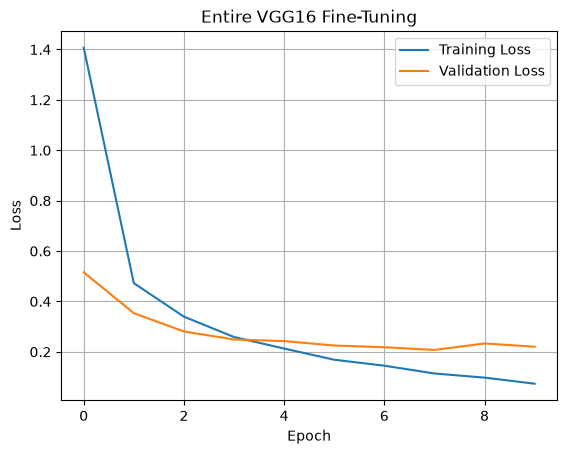

In [11]:
# 9. Plot loss curves for entire fine-tuning
plt.plot(history1.history["loss"], label="Training Loss")
plt.plot(history1.history["val_loss"], label="Validation Loss")
plt.title("Entire VGG16 Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

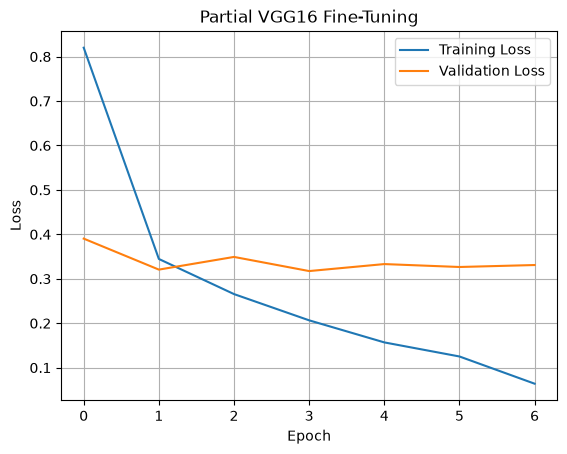

In [12]:
# 10. Plot loss curves for partial fine-tuning
plt.plot(history2.history["loss"], label="Training Loss")
plt.plot(history2.history["val_loss"], label="Validation Loss")
plt.title("Partial VGG16 Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [16]:
# 11. Compare test accuracy
loss1, acc1 = model1.evaluate(x_test, y_test, verbose=1)
loss2, acc2 = model2.evaluate(x_test, y_test, verbose=1)

print("Entire VGG16 Test Accuracy:", acc1)
print("Partial VGG16 Test Accuracy:", acc2)

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9273 - loss: 0.2390
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9080 - loss: 0.2866
Entire VGG16 Test Accuracy: 0.9273333549499512
Partial VGG16 Test Accuracy: 0.9079999923706055
